In [20]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


In [3]:
import pandas as pd  # For data manipulation
import numpy as np  # For numerical operations
from sklearn.model_selection import train_test_split # For splitting data
from sklearn.ensemble import RandomForestRegressor # Example model
from sklearn.metrics import mean_squared_error, r2_score # For evaluation
import matplotlib.pyplot as plt # For visualization (optional)
from scipy import stats
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
import pandas as pd


2025-07-07 06:55:53.468832: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751896553.556706 3420779 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751896553.580234 3420779 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1751896553.783525 3420779 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751896553.783550 3420779 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1751896553.783552 3420779 computation_placer.cc:177] computation placer alr

Original DataFrame shape: (260, 8)
DataFrame shape after outlier removal: (243, 8)


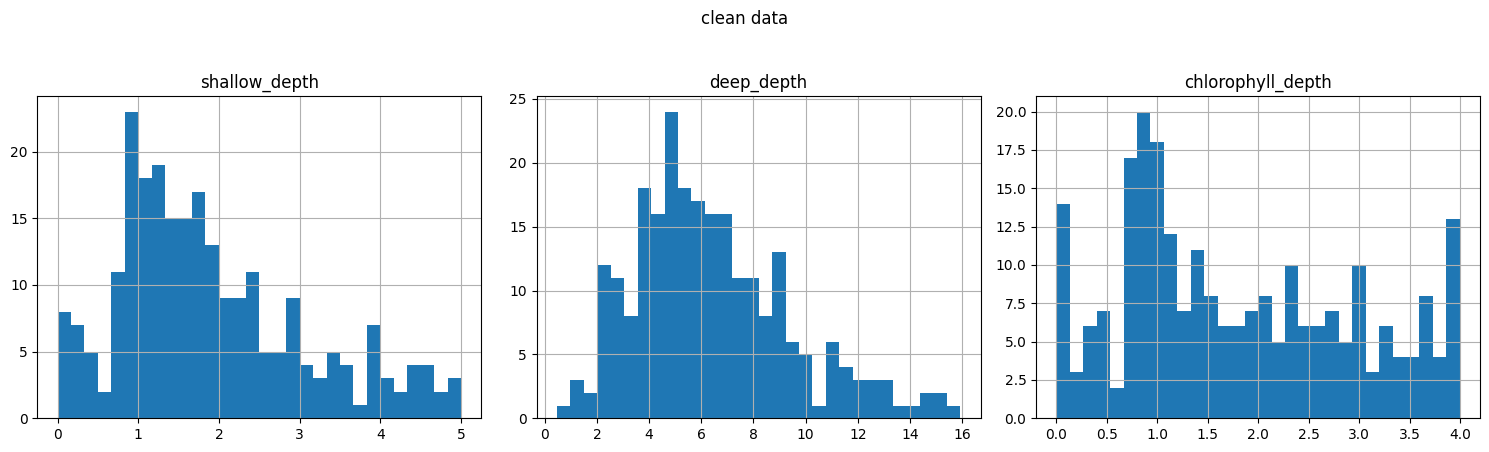

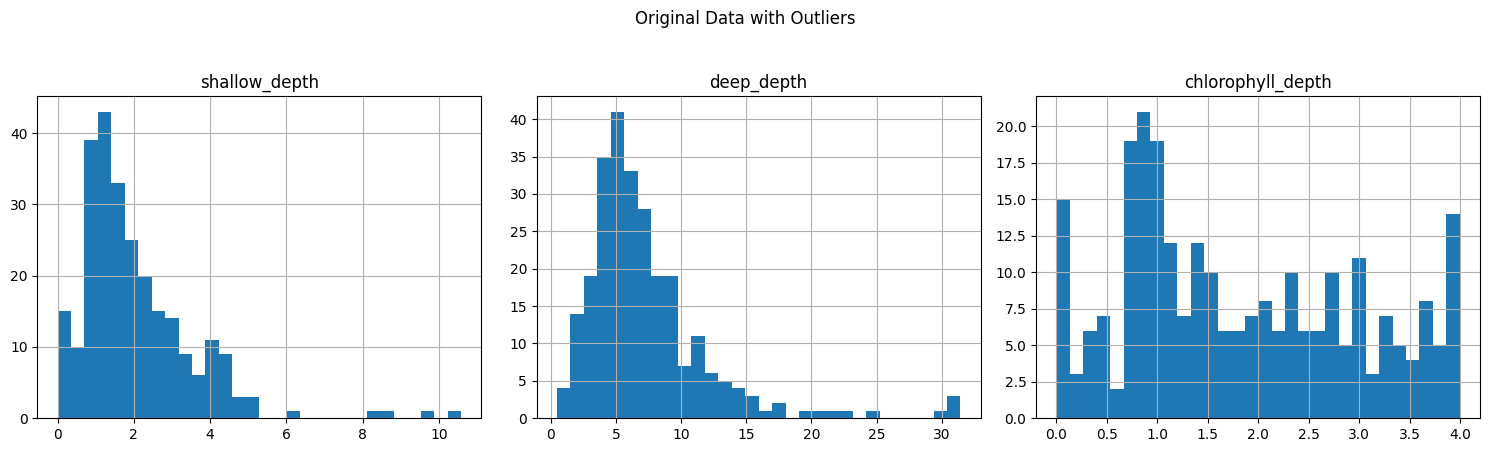

In [13]:
# 2. Load and Prepare Your Data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

import pandas as pd
from scipy import stats

feature_cols = ['shallow_depth', 'deep_depth']
target_col = 'chlorophyll_depth'

# Remove all rows where 'chlorophyll_depth' > 6
data = data[data['chlorophyll_depth'] <= 4].reset_index(drop=True)
def remove_outliers(df):
    """
    Removes rows containing outliers in 'shallow_depth', 'deep_depth', and
    'chlorophyll_depth' columns using the Z-score method.

    Args:
        df (pd.DataFrame): The input DataFrame with the specified columns.

    Returns:
        pd.DataFrame: A new DataFrame with outliers removed.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]  # Include all feature columns and target column

    for col in cols_to_check:
        if col in df_cleaned.columns:
            z = stats.zscore(df_cleaned[col])
            outlier_mask = abs(z) > 2  # You can adjust the Z-score threshold (e.g., to 2.5)
            df_cleaned = df_cleaned[~outlier_mask]
        else:
            print(f"Warning: Column '{col}' not found in the DataFrame.")
    return df_cleaned

# Assuming your DataFrame is named 'data'
# Load your data first if you haven't already
# data = pd.read_csv('your_data_file.csv', encoding='latin-1') # Make sure to use the correct encoding

# Apply the outlier removal function
if 'data' in locals():
    data_cleaned = remove_outliers(data)
    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after outlier removal:", data_cleaned.shape)
    # Now you can use 'data_cleaned' for further analysis and model building
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


import matplotlib.pyplot as plt
def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    # Combine feature columns and target column for plotting
    columns_to_plot = feature_cols + [target_col]

    # Plot a histogram for each column
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 393ms/step - loss: 2.2755 - val_loss: 1.2471
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.5391 - val_loss: 1.2766
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2824 - val_loss: 1.2148
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3764 - val_loss: 1.2332
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2216 - val_loss: 1.2822
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2353 - val_loss: 1.2411
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1012 - val_loss: 1.2936
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3553 - val_loss: 1.2359
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2669 - val_loss: 1.2611
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2495 - val_loss: 1.3072
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2841 - val_loss: 1.2782
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2122 - val_loss: 1.2483
Epoch 13/50

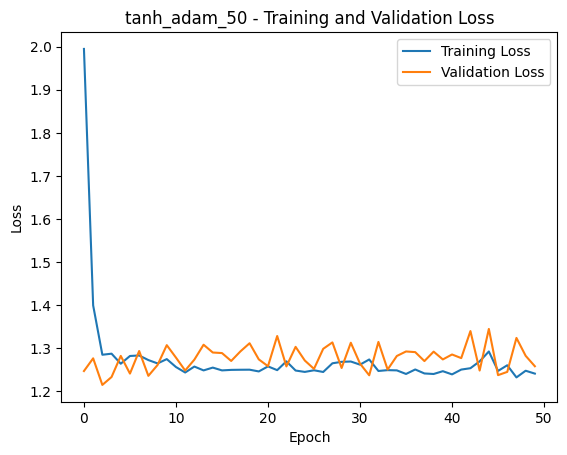

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 395ms/step - loss: 2.7312 - val_loss: 1.1910
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4756 - val_loss: 1.3808
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2077 - val_loss: 1.1895
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3426 - val_loss: 1.1969
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3489 - val_loss: 1.2267
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1738 - val_loss: 1.2735
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1625 - val_loss: 1.2430
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2977 - val_loss: 1.2766
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2109 - val_loss: 1.2871
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3489 - val_loss: 1.2781
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3646 - val_loss: 1.3458
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2840 - val_loss: 1.2679


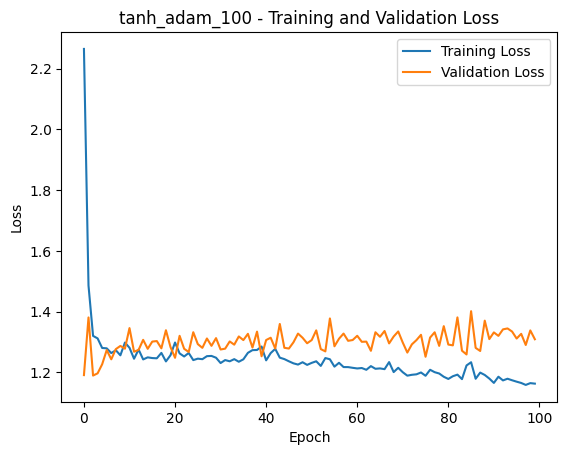

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 395ms/step - loss: 3.0961 - val_loss: 1.2199
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4139 - val_loss: 1.5748
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3964 - val_loss: 1.2229
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3992 - val_loss: 1.2017
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2439 - val_loss: 1.2668
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4157 - val_loss: 1.2478
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2511 - val_loss: 1.2300
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2410 - val_loss: 1.2217
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2428 - val_loss: 1.2576
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3064 - val_loss: 1.2840
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2433 - val_loss: 1.2699
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2613 - val_loss: 1.2775


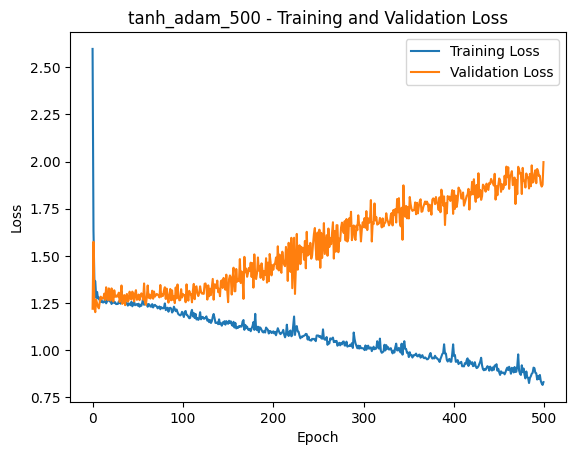

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 454ms/step - loss: 2.5906 - val_loss: 1.3172
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2403 - val_loss: 1.2864
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3255 - val_loss: 1.2697
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3247 - val_loss: 1.2689
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2825 - val_loss: 1.3820
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2706 - val_loss: 1.2747
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1916 - val_loss: 1.2990
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3441 - val_loss: 1.2757
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3285 - val_loss: 1.4690
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3505 - val_loss: 1.2888
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1870 - val_loss: 1.2742
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2631 - val_loss: 1.2874
Epoch 13/50

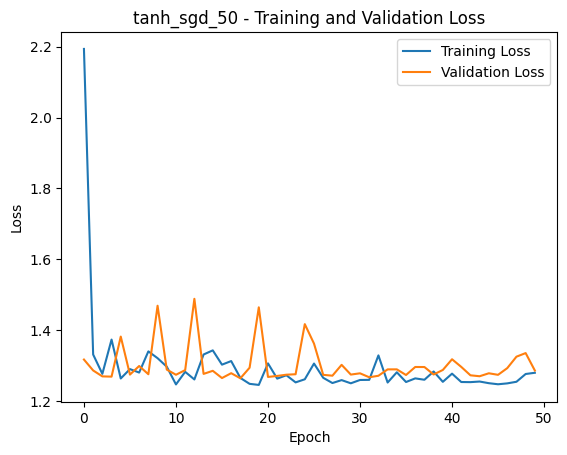

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 371ms/step - loss: 3.0680 - val_loss: 1.2788
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3409 - val_loss: 1.1921
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2927 - val_loss: 1.1992
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2811 - val_loss: 1.2430
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2411 - val_loss: 1.2127
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1812 - val_loss: 1.2221
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3249 - val_loss: 1.2361
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3000 - val_loss: 1.2390
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1205 - val_loss: 1.2433
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1973 - val_loss: 1.3014
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2200 - val_loss: 1.2444
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2517 - val_loss: 1.3117


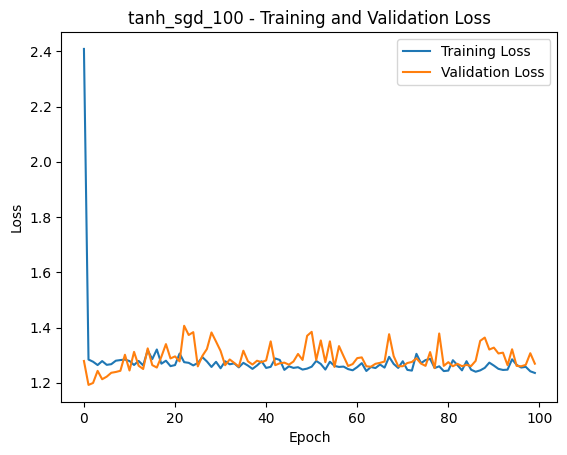

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 372ms/step - loss: 2.6637 - val_loss: 1.3793
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3308 - val_loss: 1.2362
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3320 - val_loss: 1.2751
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2568 - val_loss: 1.2462
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4029 - val_loss: 1.2477
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3373 - val_loss: 1.2638
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2379 - val_loss: 1.2840
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2762 - val_loss: 1.3800
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1790 - val_loss: 1.2564
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2924 - val_loss: 1.2897
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1551 - val_loss: 1.3761
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3108 - val_loss: 1.2631


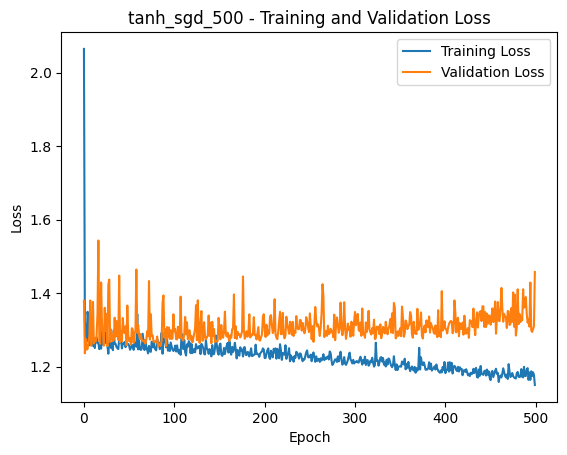

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 379ms/step - loss: 3.1872 - val_loss: 1.2213
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4660 - val_loss: 1.2098
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2675 - val_loss: 1.2500
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3509 - val_loss: 1.2650
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2468 - val_loss: 1.3751
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2342 - val_loss: 1.3646
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3993 - val_loss: 1.2493
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2670 - val_loss: 1.2004
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2925 - val_loss: 1.3334
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1937 - val_loss: 1.2615
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2233 - val_loss: 1.2691
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2182 - val_loss: 1.3701
Epoch 13/50

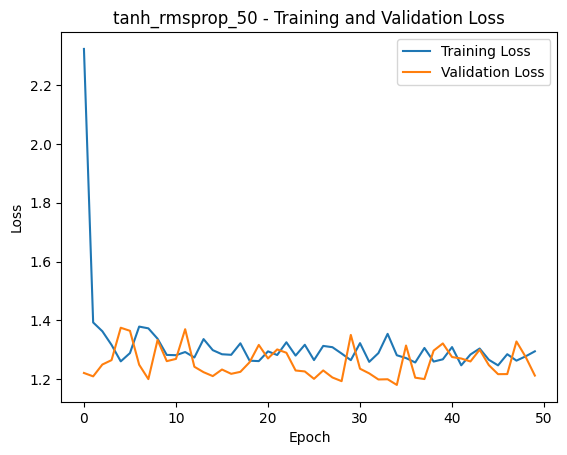

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 382ms/step - loss: 3.4900 - val_loss: 1.2197
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2865 - val_loss: 1.5923
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4307 - val_loss: 1.2227
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2880 - val_loss: 2.0860
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3200 - val_loss: 1.2871
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3361 - val_loss: 1.2415
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3753 - val_loss: 1.5855
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.6225 - val_loss: 1.2026
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2689 - val_loss: 1.1934
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2628 - val_loss: 1.2358
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3761 - val_loss: 1.5343
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2077 - val_loss: 1.3847


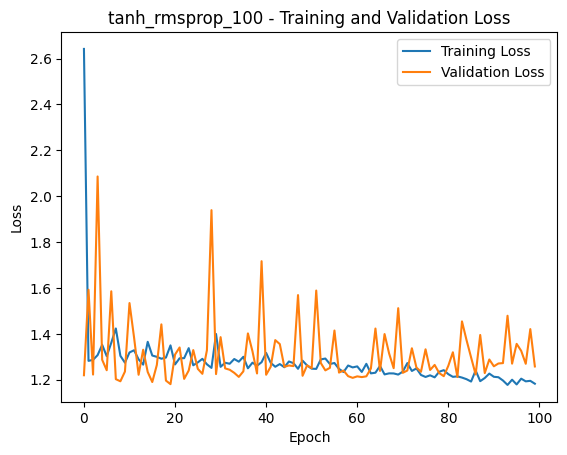

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 381ms/step - loss: 2.6499 - val_loss: 1.2601
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3042 - val_loss: 1.3326
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4142 - val_loss: 1.2020
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1846 - val_loss: 1.3737
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3293 - val_loss: 1.2156
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3520 - val_loss: 1.2817
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2438 - val_loss: 1.2230
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2198 - val_loss: 1.2440
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2123 - val_loss: 1.2204
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1670 - val_loss: 1.3125
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.1802 - val_loss: 1.2104
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2325 - val_loss: 1.2320


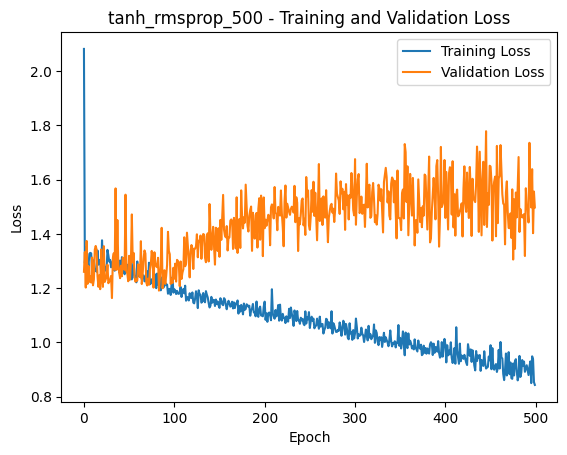

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 385ms/step - loss: 4.5591 - val_loss: 3.0352
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.8516 - val_loss: 1.7685
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.7136 - val_loss: 1.3072
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3544 - val_loss: 1.1867
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4074 - val_loss: 1.1724
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4288 - val_loss: 1.1759
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3619 - val_loss: 1.1732
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3437 - val_loss: 1.1729
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2391 - val_loss: 1.1767
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3070 - val_loss: 1.1867
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3585 - val_loss: 1.1948
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2672 - val_loss: 1.2011
Epoch 13/50

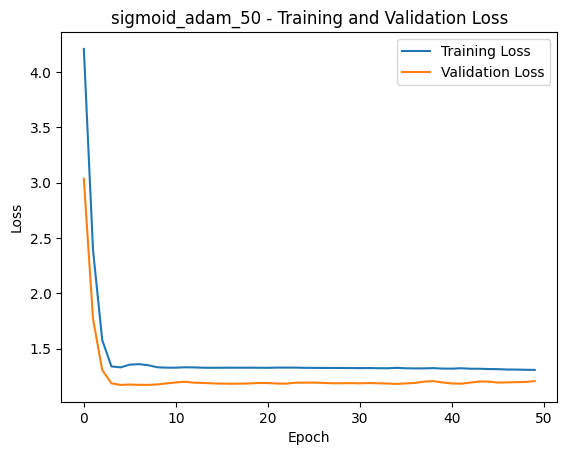

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 384ms/step - loss: 4.5933 - val_loss: 3.1385
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.7259 - val_loss: 1.7607
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.5138 - val_loss: 1.2645
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4040 - val_loss: 1.1719
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3467 - val_loss: 1.1847
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3248 - val_loss: 1.1855
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4221 - val_loss: 1.1731
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2741 - val_loss: 1.1759
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3484 - val_loss: 1.1946
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2967 - val_loss: 1.2091
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2250 - val_loss: 1.2014
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3043 - val_loss: 1.1924


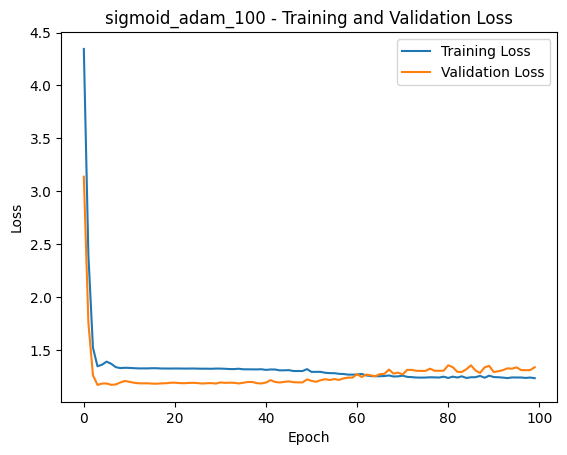

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 391ms/step - loss: 3.6945 - val_loss: 2.3256
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.9961 - val_loss: 1.4064
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3928 - val_loss: 1.1841
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3348 - val_loss: 1.1758
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4517 - val_loss: 1.1802
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4237 - val_loss: 1.1745
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4313 - val_loss: 1.1735
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3033 - val_loss: 1.1861
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2869 - val_loss: 1.2006
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3240 - val_loss: 1.2032
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3529 - val_loss: 1.2054
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3658 - val_loss: 1.1941


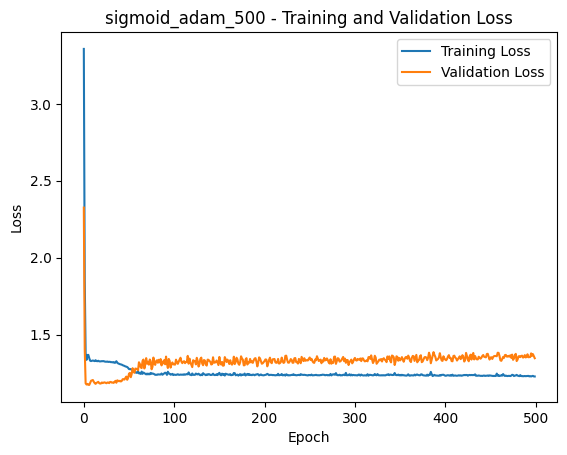

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 362ms/step - loss: 2.6554 - val_loss: 1.3063
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4385 - val_loss: 1.1961
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3143 - val_loss: 1.1967
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2950 - val_loss: 1.1856
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2809 - val_loss: 1.1852
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3468 - val_loss: 1.1819
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3342 - val_loss: 1.1908
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3500 - val_loss: 1.1872
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2676 - val_loss: 1.1836
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3309 - val_loss: 1.1929
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2136 - val_loss: 1.1752
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1623 - val_loss: 1.1730
Epoch 13/50

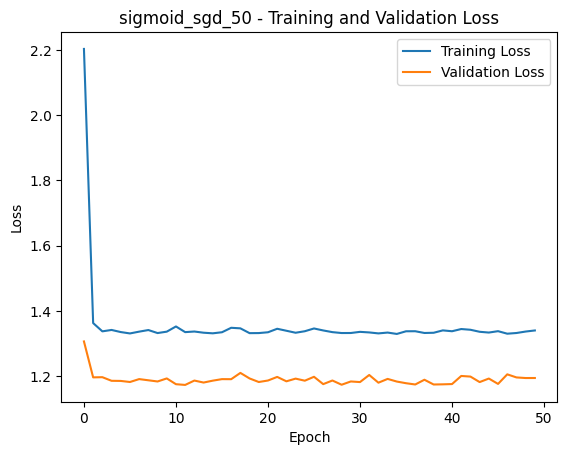

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 362ms/step - loss: 1.8996 - val_loss: 1.2586
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4354 - val_loss: 1.1954
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3286 - val_loss: 1.1753
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2993 - val_loss: 1.1910
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3687 - val_loss: 1.1797
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3385 - val_loss: 1.1880
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3609 - val_loss: 1.2040
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4239 - val_loss: 1.1965
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3505 - val_loss: 1.1992
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3709 - val_loss: 1.2118
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3108 - val_loss: 1.2050
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2896 - val_loss: 1.1967


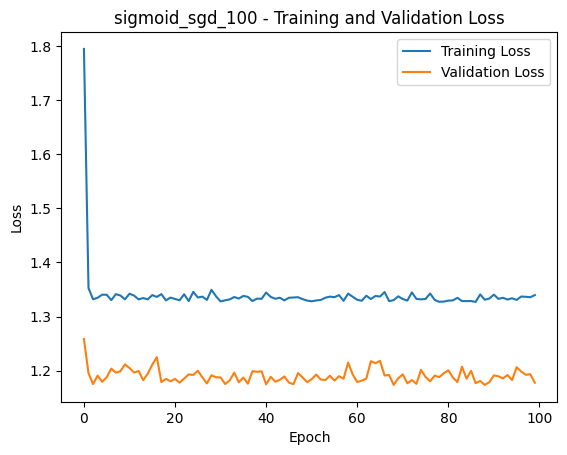

/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 367ms/step - loss: 2.1023 - val_loss: 1.2693
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3860 - val_loss: 1.2278
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3263 - val_loss: 1.1941
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.3671 - val_loss: 1.2021
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3358 - val_loss: 1.1939
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2931 - val_loss: 1.2000
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2947 - val_loss: 1.1915
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.2230 - val_loss: 1.1809
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2535 - val_loss: 1.2139
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.2916 - val_loss: 1.1926
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.2704 - val_loss: 1.1717
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3439 - val_l

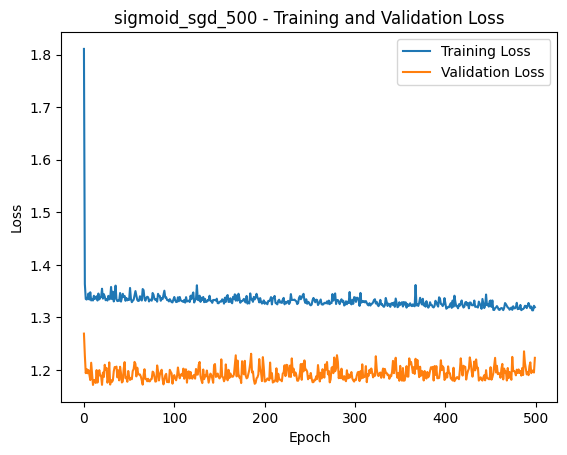

Epoch 1/50


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 374ms/step - loss: 2.2563 - val_loss: 1.2986
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3167 - val_loss: 1.2035
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3253 - val_loss: 1.1934
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3375 - val_loss: 1.1964
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2796 - val_loss: 1.2117
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3062 - val_loss: 1.1823
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3354 - val_loss: 1.1860
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4069 - val_loss: 1.1865
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3010 - val_loss: 1.1939
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2881 - val_loss: 1.1759
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3136 - val_loss: 1.2236
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2865 - val_loss: 1.1950
Epoch 13/50

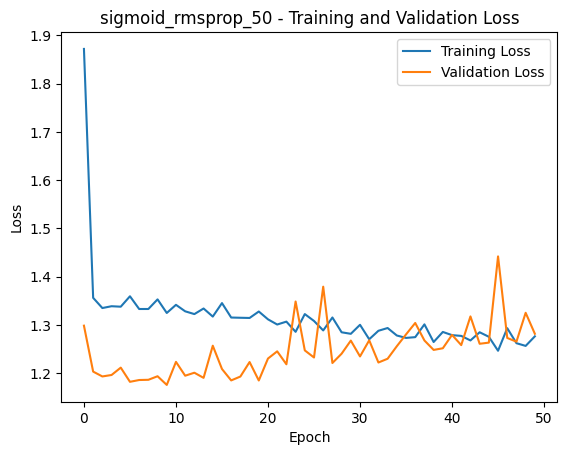

Epoch 1/100


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 376ms/step - loss: 4.3924 - val_loss: 2.2123
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.8374 - val_loss: 1.5236
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4427 - val_loss: 1.3014
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3717 - val_loss: 1.2230
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2871 - val_loss: 1.1932
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2646 - val_loss: 1.1908
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3361 - val_loss: 1.1951
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4109 - val_loss: 1.1896
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3695 - val_loss: 1.1838
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2903 - val_loss: 1.1842
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3576 - val_loss: 1.1999
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3650 - val_loss: 1.1783


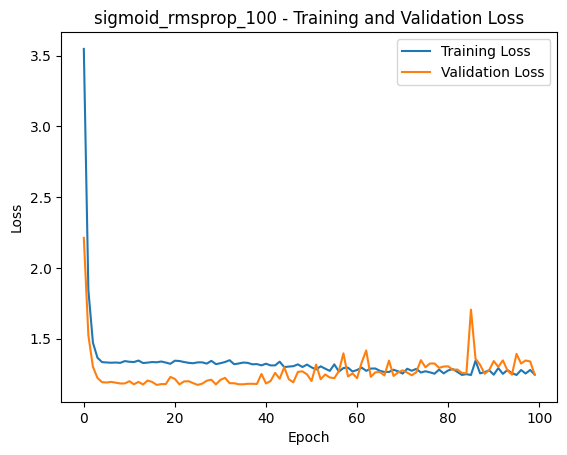

Epoch 1/500


/home/jpoulet/Chlorocline Predicter/.venv/lib/python3.10/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 374ms/step - loss: 2.4956 - val_loss: 1.4677
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.4587 - val_loss: 1.2646
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3454 - val_loss: 1.1960
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3103 - val_loss: 1.1900
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.2602 - val_loss: 1.1765
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3259 - val_loss: 1.1732
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3316 - val_loss: 1.1946
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3106 - val_loss: 1.1963
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.3016 - val_loss: 1.1785
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.2695 - val_loss: 1.2039
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3612 - val_loss: 1.2099
Epoch 12/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3113 - val_loss: 1.1790


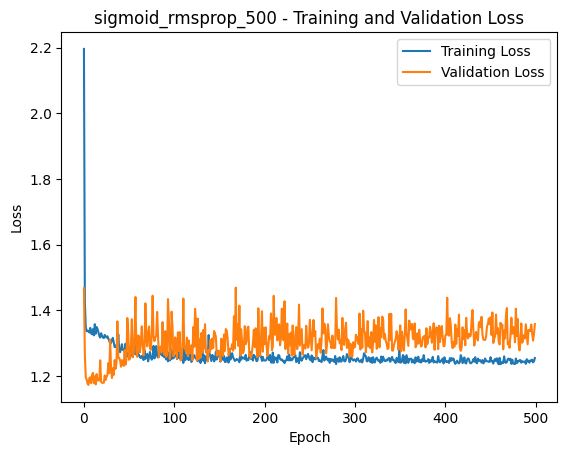

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Assuming you have run the data splitting code and have train_df, val_df, test_df
train_df, temp_df = train_test_split(data, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]




# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [50, 100, 500]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            model = Sequential([
                Dense(256, activation=activation, input_shape=(x_train.shape[1],)),  # Input layer
                Dense(128, activation=activation),  # Hidden layer
                Dense(64, activation=activation),  # Hidden layer
                Dense(32, activation=activation),  # Hidden layer
                Dense(1)  # Output layer (regression)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            # Store the model and its performance
            # You can use a dictionary or a list to store the models and their performance
            # For example:
            # models[activation + '_' + optimizer + '_' + str(epoch)] = (model, mse)
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [15]:
# Sort models by MSE (lowest to highest)
sorted_models = sorted(models.items(), key=lambda item: item[1][1] if not np.isnan(item[1][1]) else float('inf'))
print("Models sorted by Test MSE (lowest to highest):")
for name, (mdl, mse_val) in sorted_models:
  print(f"{name}: Test MSE = {mse_val}")

Models sorted by Test MSE (lowest to highest):
tanh_adam_500: Test MSE = 1.4501723051071167
tanh_rmsprop_500: Test MSE = 1.4830381870269775
tanh_adam_100: Test MSE = 1.4980957508087158
tanh_rmsprop_50: Test MSE = 1.4988181591033936
tanh_sgd_100: Test MSE = 1.5096924304962158
tanh_adam_50: Test MSE = 1.5098408460617065
sigmoid_rmsprop_50: Test MSE = 1.5140762329101562
sigmoid_sgd_100: Test MSE = 1.5170063972473145
tanh_rmsprop_100: Test MSE = 1.5187923908233643
sigmoid_adam_50: Test MSE = 1.5204981565475464
tanh_sgd_50: Test MSE = 1.5234841108322144
sigmoid_rmsprop_100: Test MSE = 1.5297635793685913
sigmoid_sgd_50: Test MSE = 1.5312448740005493
sigmoid_sgd_500: Test MSE = 1.5395636558532715
sigmoid_adam_100: Test MSE = 1.5555578470230103
sigmoid_adam_500: Test MSE = 1.560570478439331
sigmoid_rmsprop_500: Test MSE = 1.5637056827545166
tanh_sgd_500: Test MSE = 1.6281168460845947


Model: tanh_adam_50, Test MSE: 1.5098408460617065
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 512ms/step


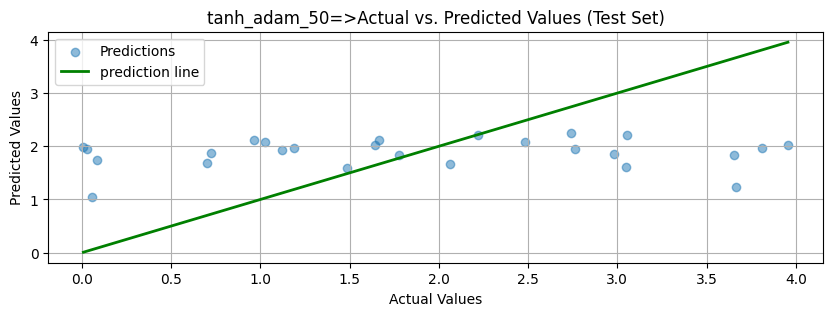

Model: tanh_adam_100, Test MSE: 1.4980957508087158
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 520ms/step


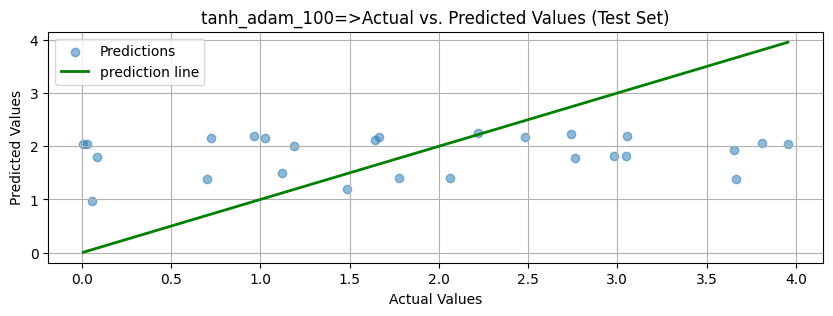

Model: tanh_adam_500, Test MSE: 1.4501723051071167
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step


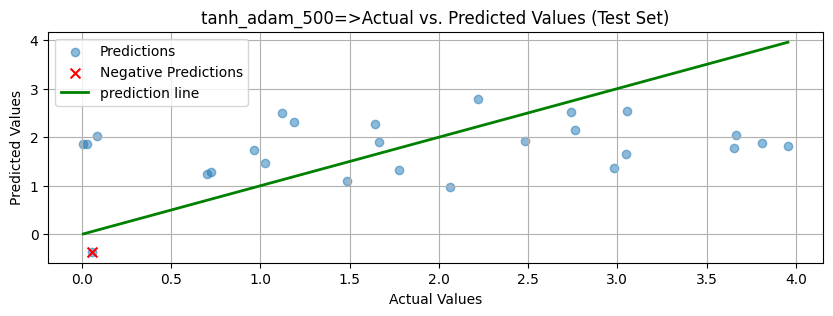

Model: tanh_sgd_50, Test MSE: 1.5234841108322144
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 533ms/step


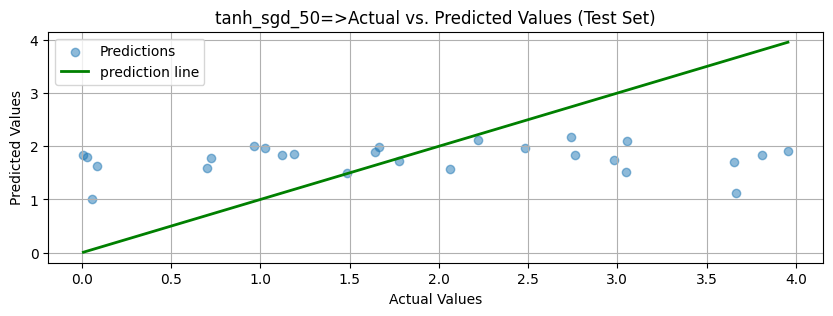

Model: tanh_sgd_100, Test MSE: 1.5096924304962158
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 507ms/step


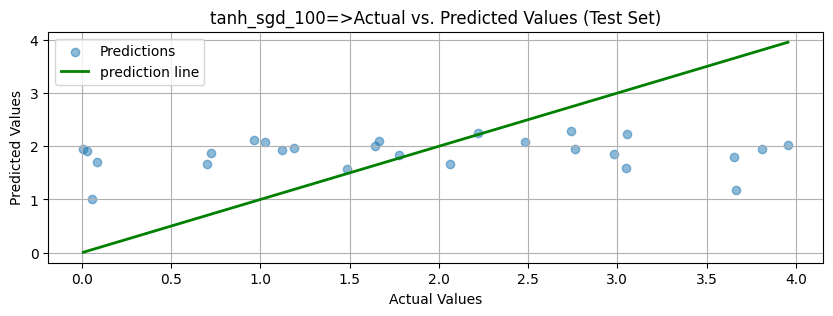

Model: tanh_sgd_500, Test MSE: 1.6281168460845947
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 530ms/step


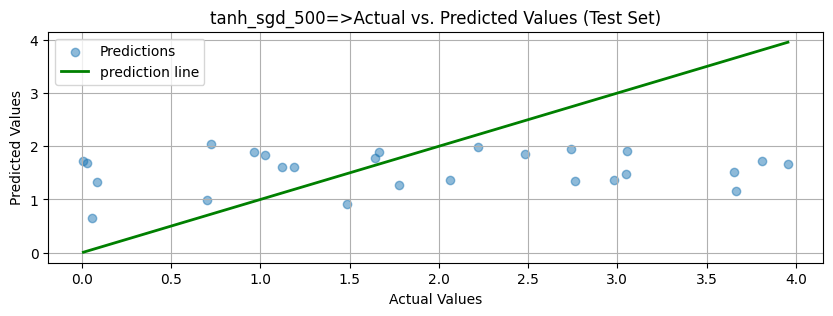

Model: tanh_rmsprop_50, Test MSE: 1.4988181591033936
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 528ms/step


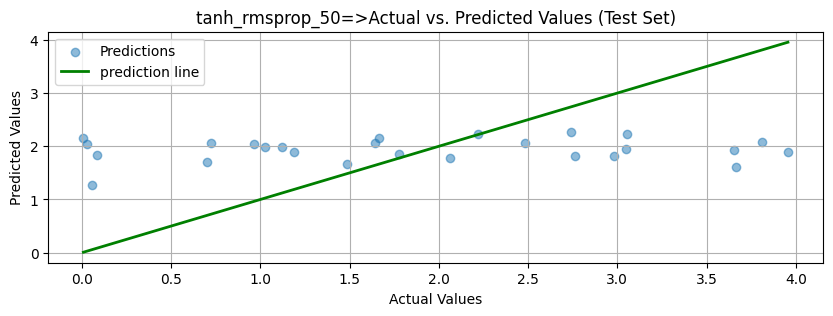

Model: tanh_rmsprop_100, Test MSE: 1.5187923908233643
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 531ms/step


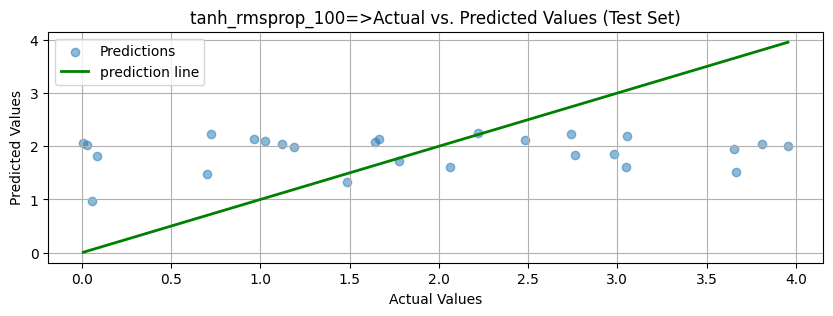

Model: tanh_rmsprop_500, Test MSE: 1.4830381870269775
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 517ms/step


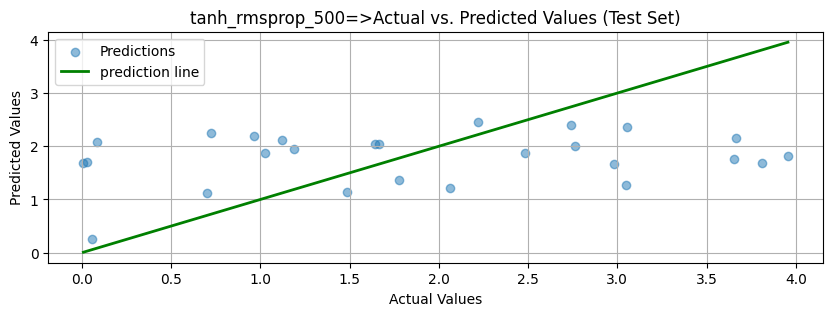

Model: sigmoid_adam_50, Test MSE: 1.5204981565475464
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 530ms/step


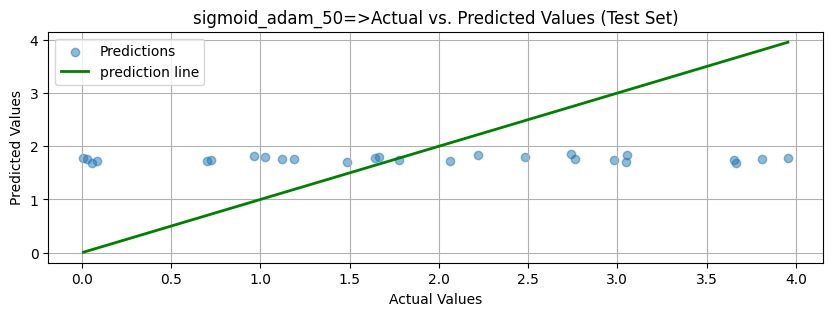

Model: sigmoid_adam_100, Test MSE: 1.5555578470230103
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 519ms/step


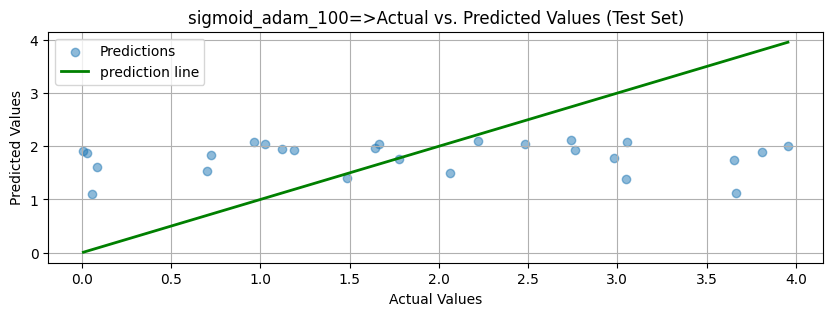

Model: sigmoid_adam_500, Test MSE: 1.560570478439331
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 536ms/step


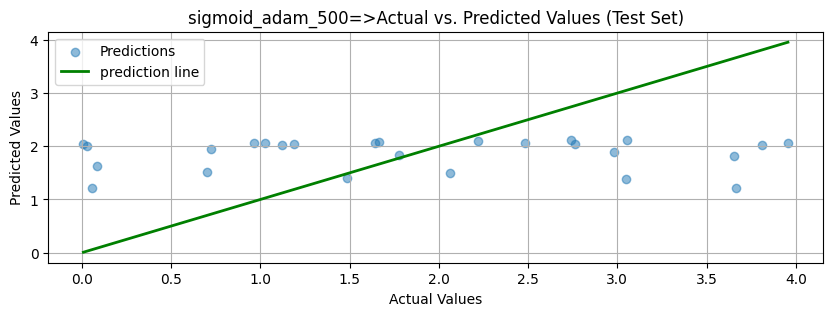

Model: sigmoid_sgd_50, Test MSE: 1.5312448740005493
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 528ms/step


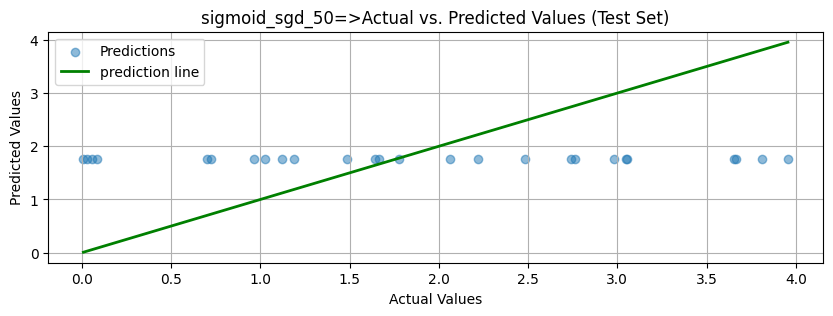

Model: sigmoid_sgd_100, Test MSE: 1.5170063972473145
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 521ms/step


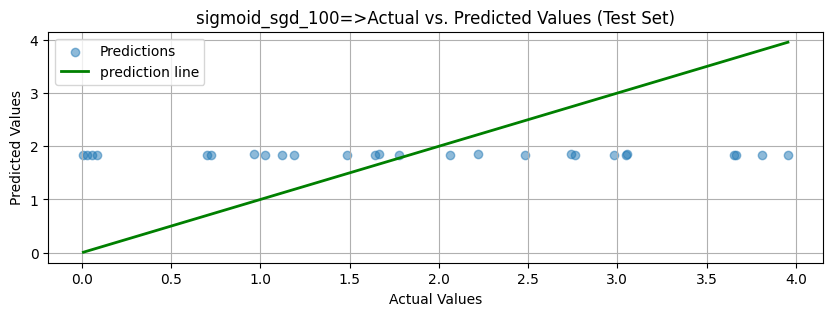

Model: sigmoid_sgd_500, Test MSE: 1.5395636558532715
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 537ms/step


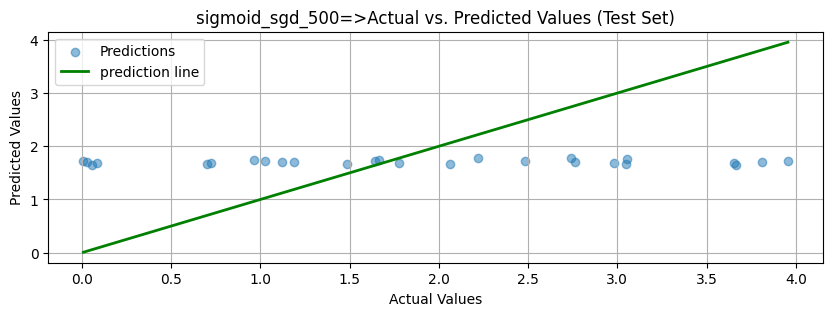

Model: sigmoid_rmsprop_50, Test MSE: 1.5140762329101562
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 529ms/step


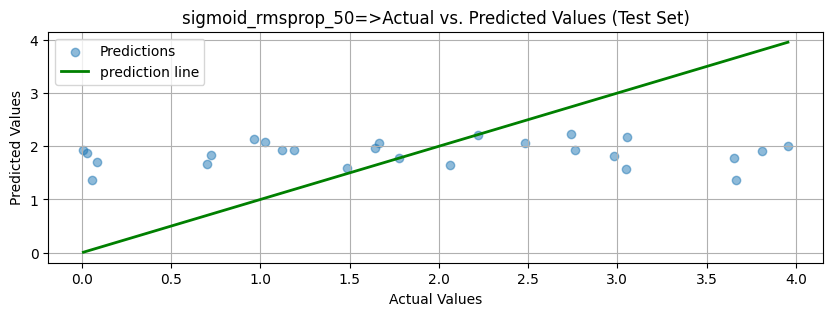

Model: sigmoid_rmsprop_100, Test MSE: 1.5297635793685913
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 534ms/step


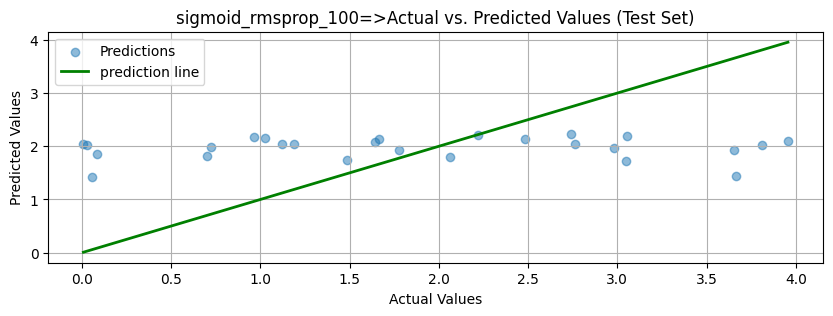

Model: sigmoid_rmsprop_500, Test MSE: 1.5637056827545166
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 538ms/step


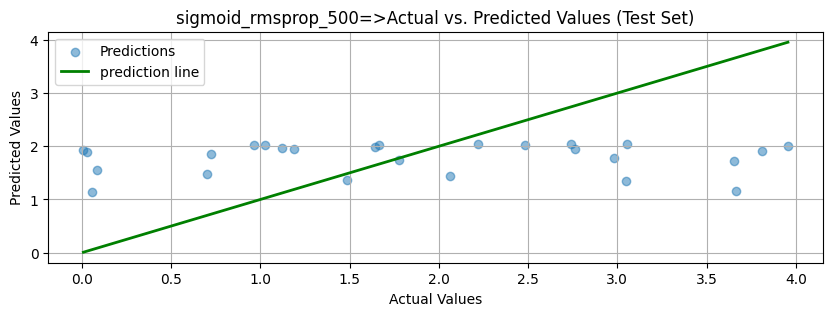

In [16]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")